# 7. Prompt sensitivity

Three prompts on the same texts: the baseline, a rewording with the same information, and a prompt that adds the word "strict" (it changes what is asked). The stand-in model reacts to that word, like a model that is sensitive to the wording.

In [1]:
import tempfile
from pathlib import Path

import pandas as pd

from polalign import annotate, load_model_inputs, run_dataset, save_au_tables
from polalign.toy import toy_ratings, toy_spec

pd.set_option("display.width", 160)
result = run_dataset(toy_spec(), raw=toy_ratings())                      # the toy dataset
out = Path(tempfile.mkdtemp())                                           # where the runs are saved
save_au_tables({"toy": result.au}, out)                                  # aposteriori_for_models.csv: the attributed texts
inputs = load_model_inputs(out / "aposteriori_for_models.csv")
WORD = {"toy": "comment"}                                                # how a text is called in a prompt

## The same texts for every prompt

`sample_inputs` draws a seeded random sample, so every prompt and model sees the same texts (here the toy data is small, so we take 30).

In [2]:
from polalign import sample_inputs

sample = sample_inputs(inputs, 30, seed=42)
{name: len(table) for name, table in sample.items()}

{'toy': 30}

In [3]:
from polalign.toy import standin_model

model = standin_model()
prompts = {
    "baseline": lambda texts, item: f"Rate how toxic each {item} is from 1 to 5.\nReply: score=<1-5>, label=<toxic/civil>\n{texts}",
    "reworded": lambda texts, item: f"Here are some {item}s. For each, give a toxicity score from 1 to 5 and a label.\nReply: score=<1-5>, label=<toxic/civil>\n{texts}",
    "strict": lambda texts, item: f"Be strict. Rate how toxic each {item} is from 1 to 5.\nReply: score=<1-5>, label=<toxic/civil>\n{texts}",
}
for run, prompt in prompts.items():                                       # a new run name for every prompt
    annotate(model, sample, out, prompt=prompt, run=run, item_words=WORD, show_progress=False)

## Compare the runs

A rewording with the same information should keep the labels. Adding "strict" does not.

In [4]:
from polalign import compare_prompts

table = compare_prompts(out, datasets=["toy"], runs=list(prompts), models=["standin"], reps=1_000, seed=42)
table[["first", "second", "n_texts", "label_agreement_pct", "label_agreement_ci", "kappa", "weighted_kappa", "spearman", "mean_shift"]]

,first,second,n_texts,label_agreement_pct,label_agreement_ci,kappa,weighted_kappa,spearman,mean_shift
0,baseline,reworded,30,100.0,"(100.0, 100.0)",1.0,1.0000,1.0,0.0
1,baseline,strict,30,60.0,"(43.3333, 76.6667)",0.0,0.7059,1.0,0.8
2,reworded,strict,30,60.0,"(43.3333, 76.6667)",0.0,0.7059,1.0,0.8


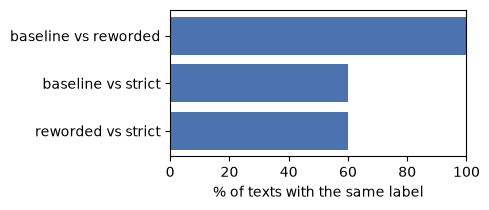

In [5]:
import matplotlib.pyplot as plt

names = table["first"] + " vs " + table["second"]
fig, ax = plt.subplots(figsize=(5, 2.2))
ax.barh(names, table["label_agreement_pct"], color="#4C72B0")
ax.set_xlim(0, 100)
ax.set_xlabel("% of texts with the same label")
ax.invert_yaxis()
plt.tight_layout()